# Snow Disappearance Date (DSD)

This notebook shows an example of searching and downloading PlanetScope imagery, predicting snow covered area (SCA), and calculating the **Date of Snow Disappearance (DSD)**, **DSD anomaly**, and **DSD uncertainty**.

In [20]:
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import rioxarray as rxr

import planetsca as ps

plt.rcParams["font.family"] = "DeJavu Serif"
plt.rcParams["font.serif"] = ["Times New Roman"]

## 1. Search for PlanetScope Imagery

Use `planetsca.search` to build the date range, geometry, and cloud cover (`<= 5%`) filters and query the Planet API.

In [14]:
api_key = os.environ.get("PLANET_API_KEY", "YOUR API KEY")

# Example bounds: Devil's Postpile (DPO) from Pflug et al. Using Commercial Satellite Imagery to Reconstruct 3 m and Daily Spring Snow Water (2024) [minLon, minLat, maxLon, maxLat]
bounds = [-119.07465195862622, 37.60366497906669, -119.05576088657531, 37.61889954813522]

date_range_filter = ps.search.make_date_range_filter(
    "2022-03-01T00:00:00.000Z", "2022-08-01T00:00:00.000Z"
)
geometry_filter = ps.search.make_geometry_filter_from_bounds(bounds)
# Or from a GeoJSON file (can be simplified first with ps.simplify_aoi.simplify):
# geometry_filter = ps.search.make_geometry_filter_from_geojson("my_study_area.geojson")

cloud_filter = ps.search.make_cloud_cover_filter(0.05)

filter = ps.search.combine_filters([date_range_filter, geometry_filter, cloud_filter])

In [15]:
search_results_gdf = ps.search.search(api_key, filter)
search_results_gdf

Search returned 146 items.


,geometry,acquired,anomalous_pixels,clear_confidence_percent,clear_percent,cloud_cover,cloud_percent,ground_control,gsd,heavy_haze_percent,...,strip_id,sun_azimuth,sun_elevation,updated,view_angle,visible_confidence_percent,visible_percent,intersection_area,overlap_percentage,id
0,"POLYGON ((-119.29244 37.68408, -119.35711 37.4...",2022-03-11T17:48:58.607066Z,0.00,62,26,0.01,1,True,4.0,0,...,5479204,134.4,38.1,2025-02-14T19:41:27Z,1.2,57,99,0.000288,100.000000,20220311_174858_60_245d
1,"POLYGON ((-119.27527 37.83259, -119.34011 37.6...",2022-03-11T17:48:56.309708Z,0.00,57,20,0.05,5,True,4.0,0,...,5479204,134.5,38.1,2025-02-14T19:41:48Z,1.4,55,95,0.000288,100.000000,20220311_174856_30_245d
2,"POLYGON ((-119.32324 37.6827, -119.37506 37.49...",2022-05-12T17:49:01.155498Z,0.00,78,61,0.00,0,True,4.0,0,...,5632679,116.8,56.7,2025-02-14T19:42:54Z,1.0,62,100,0.000288,100.000000,20220512_174901_15_2465
3,"POLYGON ((-119.29755 37.81939, -119.34915 37.6...",2022-05-12T17:48:58.85814Z,0.00,76,43,0.02,2,True,4.0,0,...,5632679,117.0,56.7,2025-02-14T19:42:30Z,0.9,61,98,0.000288,100.000000,20220512_174858_85_2465
4,"POLYGON ((-119.22785 37.67716, -119.27896 37.4...",2022-07-07T18:16:49.077923Z,0.00,94,99,0.00,0,True,4.0,0,...,5769030,116.9,63.4,2025-02-14T19:41:33Z,5.0,67,100,0.000288,100.000000,20220707_181649_07_2470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,"POLYGON ((-119.39242 37.77903, -119.44333 37.5...",2022-03-07T18:03:54.39617Z,0.00,72,6,0.01,1,True,3.9,0,...,5465717,138.7,38.2,2023-01-29T01:33:11Z,4.0,72,99,0.000288,100.000000,20220307_180354_39_2262
142,"POLYGON ((-119.07809 37.65062, -119.1313 37.46...",2022-03-07T17:51:09.351749Z,0.00,64,9,0.01,1,True,4.1,0,...,5465817,135.5,36.7,2023-01-30T12:21:55Z,5.0,69,99,0.000288,100.000000,20220307_175109_35_2440
143,"POLYGON ((-119.03741 37.79354, -119.09057 37.6...",2022-03-07T17:51:07.053869Z,0.00,83,31,0.00,0,True,4.1,0,...,5465817,135.6,36.6,2023-01-30T12:21:55Z,5.0,82,100,0.000288,100.000000,20220307_175107_05_2440
144,"POLYGON ((-119.04673 37.63974, -119.06582 37.5...",2022-03-02T18:14:55.012171Z,0.15,58,28,0.00,0,True,3.7,0,...,5450148,143.5,38.4,2022-03-03T06:35:05Z,2.1,55,100,0.000001,0.427139,20220302_181455_1001


Exclude scenes that overlap the study area by less than 99% (matching `CSDA_scripts/0_PlanetDownload.ipynb`) so all clipped scenes cover the full domain grid:

In [16]:
search_results_gdf.drop(
    search_results_gdf[search_results_gdf.overlap_percentage < 99].index, inplace=True
)
id_list = search_results_gdf.id.to_list()
id_list

['20220311_174858_60_245d',
 '20220311_174856_30_245d',
 '20220512_174901_15_2465',
 '20220512_174858_85_2465',
 '20220707_181649_07_2470',
 '20220428_175143_81_220b',
 '20220724_175008_21_2421',
 '20220721_174800_57_245c',
 '20220712_182823_93_2424',
 '20220710_183505_76_2403',
 '20220711_174317_52_2428',
 '20220709_183510_29_2414',
 '20220707_181752_97_249b',
 '20220706_183741_21_2402',
 '20220705_181642_90_249a',
 '20220701_174642_88_2429',
 '20220630_181555_73_2499',
 '20220628_181632_95_247b',
 '20220624_181955_99_249c',
 '20220624_174150_46_2463',
 '20220618_174550_02_2459',
 '20220619_181902_91_24a3',
 '20220615_174515_24_2420',
 '20220616_181833_04_249b',
 '20220616_175323_22_2212',
 '20220615_181710_81_2461',
 '20220614_183259_47_2414',
 '20220613_174642_05_2453',
 '20220611_174613_44_2455',
 '20220608_175019_46_2465',
 '20220610_174534_02_2460',
 '20220608_182106_30_247e',
 '20220608_182103_98_247e',
 '20220607_183342_83_241c',
 '20220606_181702_15_247c',
 '20220606_181659_84

## 2. Order and Download Clipped Imagery

`ps.download.order` builds the Planet Orders v2 payload with the `clip` tool and `analytic_sr_udm2` bundle and submits the order. `ps.download.download` polls every 60 seconds and downloads the clipped files once ready.

In [17]:
order_url = ps.download.order(api_key, id_list, filter)

Submitted a total of 109 image ids: accepted a total of 109 ids
Order URL: https://api.planet.com/compute/ops/orders/v2/4a296192-6a7d-485c-9af2-32b39be5e05a


In [18]:
out_dirpath = "./example_images"
ps.download.download(api_key, order_url, out_dirpath=out_dirpath)

Attempting to download
data not ready yet, this was attempt number 1
will automatically try again in 60 seconds
data not ready yet, this was attempt number 2
will automatically try again in 60 seconds
data not ready yet, this was attempt number 3
will automatically try again in 60 seconds
data not ready yet, this was attempt number 4
will automatically try again in 60 seconds
data not ready yet, this was attempt number 5
will automatically try again in 60 seconds
320 items to download
downloading 4a296192-6a7d-485c-9af2-32b39be5e05a/PSScene/20220705_181642_90_249a_metadata.json to example_images/4a296192-6a7d-485c-9af2-32b39be5e05a/PSScene/20220705_181642_90_249a_metadata.json
downloading 4a296192-6a7d-485c-9af2-32b39be5e05a/PSScene/20220705_181642_90_249a_3B_AnalyticMS_metadata_clip.xml to example_images/4a296192-6a7d-485c-9af2-32b39be5e05a/PSScene/20220705_181642_90_249a_3B_AnalyticMS_metadata_clip.xml
downloading 4a296192-6a7d-485c-9af2-32b39be5e05a/PSScene/20220705_181642_90_249a_3

## 3. Predict Snow-Covered Area (`*_SCA.tif`)

Retrieve the pre-trained model from Hugging Face (`ps.download.retrieve_model_onnx`) and pass `out_dirpath` directly to `ps.predict.predict_sca_onnx`. When given a directory path, `predict_sca_onnx` automatically finds all `/**/*SR*.tif` files recursively and writes `<scene>_SCA.tif` rasters (`0` = no snow, `1` = snow, `9` = nodata).

In [21]:
model = ps.download.retrieve_model_onnx()
output_dirpath = "./example_images/SCA/"

sr_files = sorted(
    f
    for f in glob.glob(f"{out_dirpath}/**/*SR*.tif", recursive=True)
    if not f.endswith("_SCA.tif")
)

sca_image_paths = ps.predict.predict_sca_onnx(
    planet_path=sr_files,
    model=model,
    output_dirpath=output_dirpath,
)

Start to predict: 20220302_174913_66_2423_3B_AnalyticMS_SR_clip.tif
Image dimension: (4, 576, 569)
Save SCA map to:  ./example_images/SCA/20220302_174913_66_2423_3B_AnalyticMS_SR_clip_SCA.tif
Start to predict: 20220307_175107_05_2440_3B_AnalyticMS_SR_clip.tif
Image dimension: (4, 576, 569)
Save SCA map to:  ./example_images/SCA/20220307_175107_05_2440_3B_AnalyticMS_SR_clip_SCA.tif
Start to predict: 20220307_175109_35_2440_3B_AnalyticMS_SR_clip.tif
Image dimension: (4, 576, 569)
Save SCA map to:  ./example_images/SCA/20220307_175109_35_2440_3B_AnalyticMS_SR_clip_SCA.tif
Start to predict: 20220307_180354_39_2262_3B_AnalyticMS_SR_clip.tif
Image dimension: (4, 576, 569)
Save SCA map to:  ./example_images/SCA/20220307_180354_39_2262_3B_AnalyticMS_SR_clip_SCA.tif
Start to predict: 20220310_175153_82_2427_3B_AnalyticMS_SR_clip.tif
Image dimension: (4, 576, 569)
Save SCA map to:  ./example_images/SCA/20220310_175153_82_2427_3B_AnalyticMS_SR_clip_SCA.tif
Start to predict: 20220310_180816_30_222

Optionally inspect a raw PlanetScope RGB composite alongside its predicted SCA map using `ps.validate.calc_rgb`:

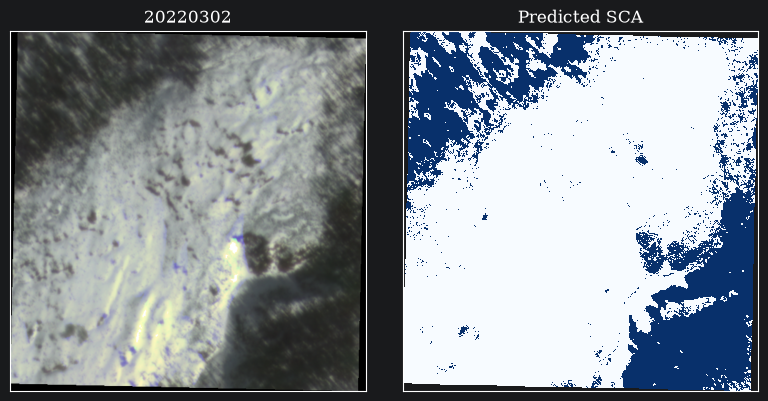

In [22]:
# Compare a sample SR image (normalized RGB via ps.validate.calc_rgb) with its predicted SCA map
if sr_files and sca_image_paths:
    ds_rgb = rxr.open_rasterio(sr_files[0])
    _, _, _, _, rgb_image = ps.validate.calc_rgb(ds_rgb)
    sca_map = rxr.open_rasterio(sca_image_paths[0]).squeeze()
    sca_map = sca_map.where(sca_map != 9)

    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(rgb_image)
    ax[0].set_title(os.path.basename(sr_files[0]).split("_")[0])
    ax[1].imshow(sca_map, vmin=0, vmax=1, cmap="Blues_r", interpolation="none")
    ax[1].set_title("Predicted SCA")
    for a in ax:
        a.set_xticks([])
        a.set_yticks([])
    plt.tight_layout()

## 4. Calculate DSD, DSD Anomaly, and DSD Uncertainty

`ps.post_process.process_DSD` stacks `<year>*SCA.tif` rasters for each year via `DSD_index` (converting `nodata=9` to `2`), fills nodata (`fill_nodata`), filters spurious single-date transitions (`DSD_qaqc`), and computes per-pixel DSD, domain-median DSD anomaly, and DSD uncertainty (`fill_DSDdates`).

In [23]:
# specify the years to process over
years = [2022]
# specify the focus year for saving DSD_stacked.npy and DSD_daydiff.npy
year_select = 2022
# specify the index of the first PS image to use for each of the "years" above
# 0 uses all March-July snow cover maps; index 7 starts on 2022-03-11
starting_array = [7]

data_direc = output_dirpath

dsd_saver, dsd_anomaly_saver, dsd_uncertain_saver = ps.post_process.process_DSD(
    years=years,
    data_direc=data_direc,
    starting_array=starting_array,
    year_select=year_select,
)

## 5. Plot DSD and DSD Anomaly

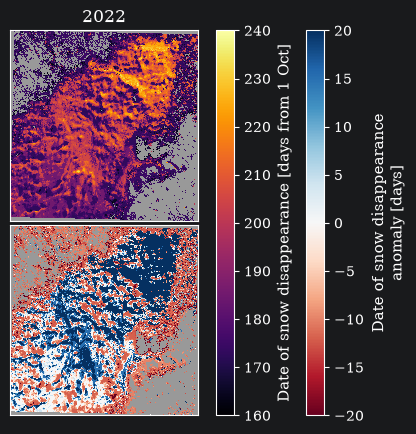

In [24]:
# perform plotting for the DSD and DSD anomaly
mask = np.sum(dsd_saver, axis=0)

fg, ax = plt.subplots(
    2,
    len(years),
    figsize=(9, 5),
    sharex="col",
    sharey="row",
    gridspec_kw={"height_ratios": [1, 1], "hspace": 0.02, "wspace": 0.05},
)

for idx, year in enumerate(years):
    data = dsd_anomaly_saver[idx, :, :]
    data[np.isnan(mask)] = np.nan
    try:
        out1 = ax[1, idx].imshow(
            data, vmin=-20, vmax=20, interpolation="none", cmap="RdBu"
        )
        ax[0, idx].set_title(year)
    except Exception:
        out1 = ax[1].imshow(data, vmin=-20, vmax=20, interpolation="none", cmap="RdBu")
        ax[0].set_title(year)

for idx, _year in enumerate(years):
    # data = dsd_uncertain_saver[idx,:,:]
    data = dsd_saver[idx, :, :]
    data[np.isnan(mask)] = np.nan
    try:
        out2 = ax[0, idx].imshow(
            data, vmin=160, vmax=240, interpolation="none", cmap="inferno"
        )
    except Exception:
        out2 = ax[0].imshow(
            data, vmin=160, vmax=240, interpolation="none", cmap="inferno"
        )

for axx in np.ravel(ax):
    axx.set_xticks([])
    axx.set_yticks([])
    axx.set_facecolor([0.6, 0.6, 0.6])

pos_bott = ax[1, -1].get_position() if len(years) > 1 else ax[1].get_position()
pos_top = ax[0, -1].get_position() if len(years) > 1 else ax[0].get_position()

cax1 = fg.add_axes([pos_bott.x1 + 0.02, pos_bott.y0, 0.02, pos_top.y1 - pos_bott.y0])
cbar1 = fg.colorbar(out2, cax=cax1, orientation="vertical")
cbar1.set_label("Date of snow disappearance [days from 1 Oct]", fontsize=11)

cax2 = fg.add_axes([pos_bott.x1 + 0.12, pos_bott.y0, 0.02, pos_top.y1 - pos_bott.y0])
cbar2 = fg.colorbar(out1, cax=cax2, orientation="vertical")
cbar2.set_label("Date of snow disappearance\nanomaly [days]", fontsize=11)